In [6]:
import cv2 as cv
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

# Sesuaikan dengan path/folder tempat Anda menyimpan gambar
# Gunakan relative path jika folder Images berada di direktori yang sama dengan script
PATH = 'image/'

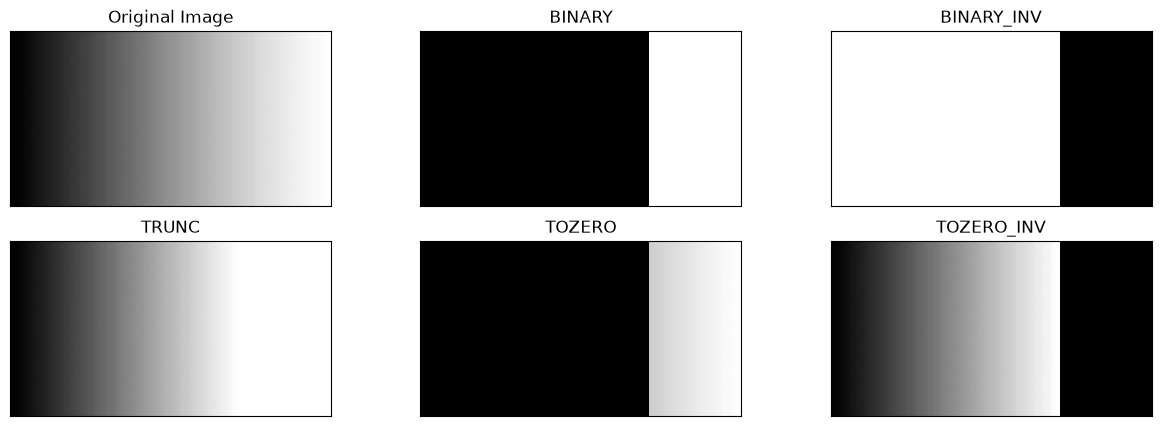

In [10]:
img = cv.imread(PATH + 'gradient.jpg', 0) # Baca sebagai grayscale
thresh = 200
maxval = 255

# Implementasi Manual sesuai ketentuan tabel
thresh1 = np.where(img > thresh, maxval, 0).astype(np.uint8)          # BINARY
thresh2 = np.where(img > thresh, 0, maxval).astype(np.uint8)          # BINARY_INV
thresh3 = np.where(img > thresh, thresh, img).astype(np.uint8)        # TRUNC
thresh4 = np.where(img > thresh, img, 0).astype(np.uint8)             # TOZERO
thresh5 = np.where(img > thresh, 0, img).astype(np.uint8)             # TOZERO_INV

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

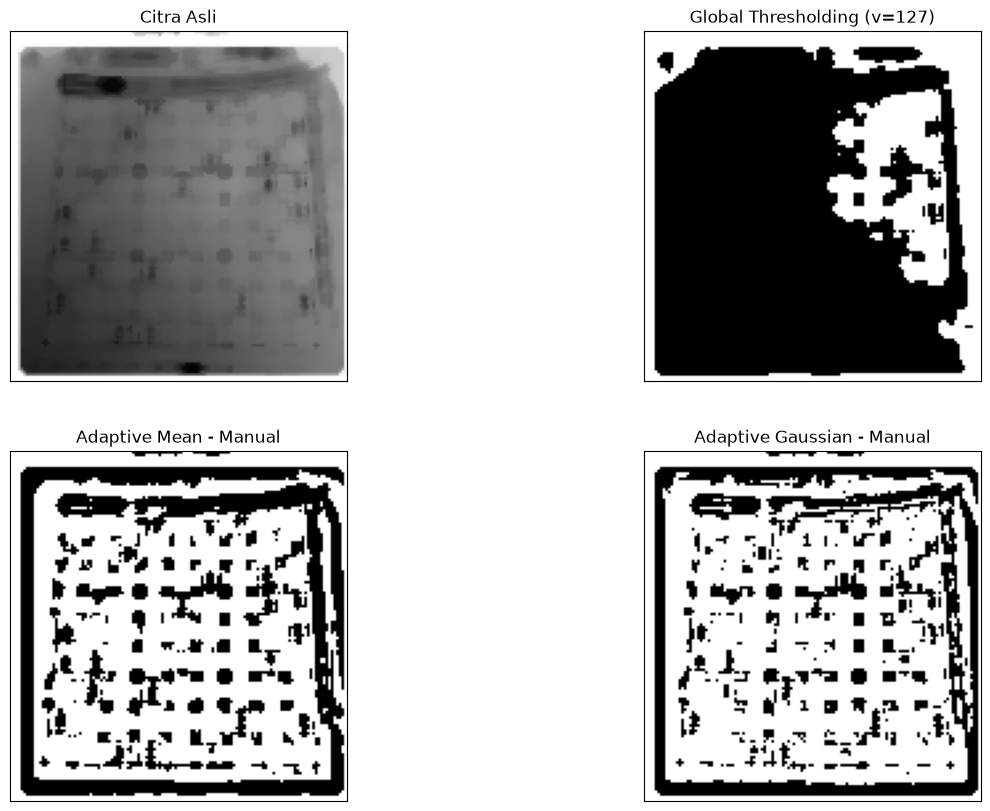

In [8]:
img = cv.imread(PATH + 'sudoku-original.jpg', 0)
img = cv.medianBlur(img, 5)

# 1. Global Thresholding Manual (v=127)
th1 = np.where(img > 127, 255, 0).astype(np.uint8)

# Parameter
block_size = 11
pad = block_size // 2
C = 2
sigma = 2

# Padding citra agar proses windowing di tepi tidak error
img_pad = np.pad(img, pad, mode='reflect').astype(np.float32)

th2 = np.zeros_like(img, dtype=np.uint8)
th3 = np.zeros_like(img, dtype=np.uint8)

# Bikin Kernel Gaussian 11x11 manual
x, y = np.mgrid[-pad:pad+1, -pad:pad+1]
g = np.exp(-(x**2 + y**2) / (2 * sigma**2))
g_kernel = g / g.sum()

# Looping manual untuk tiap piksel
for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        window = img_pad[i:i+block_size, j:j+block_size]
        
        # Adaptive Mean
        mean_val = np.mean(window)
        th2[i, j] = 255 if img[i, j] > (mean_val - C) else 0
        
        # Adaptive Gaussian
        gauss_val = np.sum(window * g_kernel)
        th3[i, j] = 255 if img[i, j] > (gauss_val - C) else 0

titles = ['Citra Asli', 'Global Thresholding (v=127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [img, th1, th2, th3]

plt.figure(figsize=(15, 10))
for i in range(len(images)):
    plt.subplot(2, 2, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

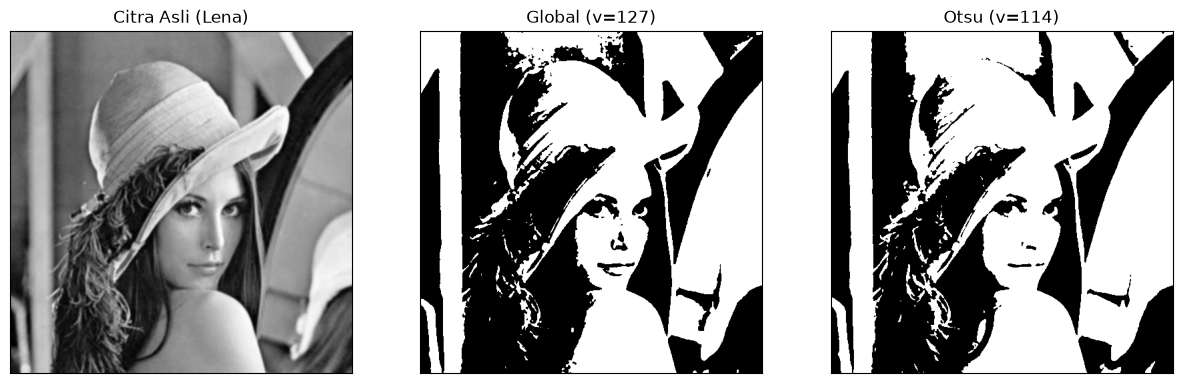

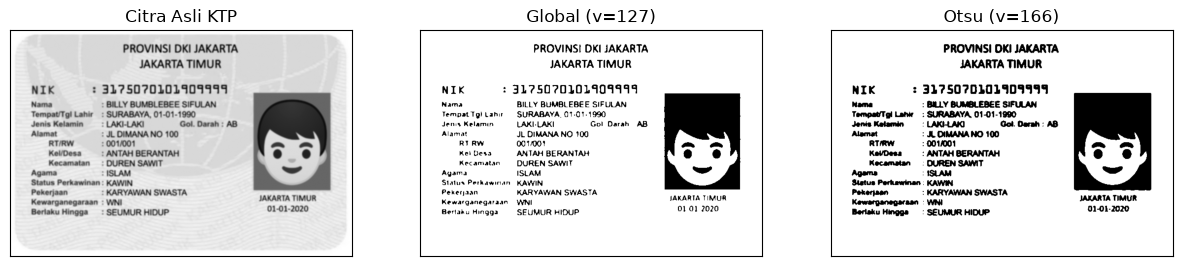

In [12]:
def otsu_manual(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0: continue
        
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        
        # Between Class Variance
        value = Wb * Wf * (mub - muf) ** 2
        
        if value > final_value:
            final_thresh = t
            final_value = value
            
    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

# Pengujian pada Lena
img_lena = cv.imread(PATH + 'lena.jpg', 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)

otsu_biner, otsu_thresh = otsu_manual(blur_lena)
th1 = np.where(blur_lena > 127, 255, 0).astype(np.uint8)

titles = ['Citra Asli (Lena)', 'Global (v=127)', f"Otsu (v={otsu_thresh})"]
images = [blur_lena, th1, otsu_biner]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(1, 3, i+1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

# Pengujian pada KTP Anda
img_ktp = cv.imread(PATH + 'ktp_fulan.jpg', 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

otsu_biner_ktp, otsu_thresh_ktp = otsu_manual(blur_ktp)
th1_ktp = np.where(blur_ktp > 127, 255, 0).astype(np.uint8)

titles_ktp = ['Citra Asli KTP', 'Global (v=127)', f"Otsu (v={otsu_thresh_ktp})"]
images_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize=(15, 5))
for i in range(len(images_ktp)):
    plt.subplot(1, 3, i+1)
    plt.imshow(images_ktp[i], 'gray')
    plt.title(titles_ktp[i])
    plt.xticks([]), plt.yticks([])
plt.show()

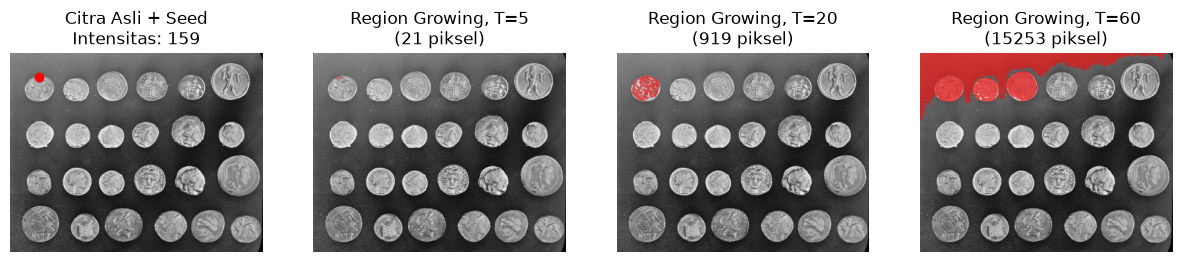

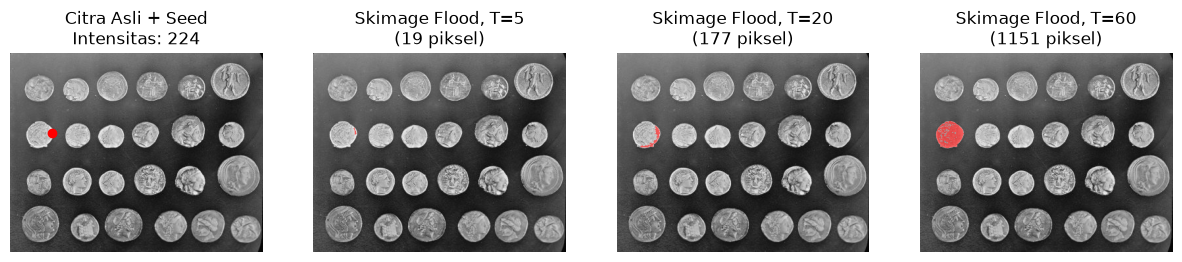

In [13]:
# A. Region Growing Manual
def region_growing(img, seed, T):
    h, w = img.shape
    segmented = np.zeros_like(img, dtype=np.uint8)
    seed_val = int(img[seed])
    
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    queue = deque([seed])
    segmented[seed] = 255
    pixel_count = 1
    
    while queue:
        x, y = queue.popleft()
        for dx, dy in neighbors:
            nx, ny = x + dx, y + dy
            if 0 <= nx < h and 0 <= ny < w and segmented[nx, ny] == 0:
                if abs(int(img[nx, ny]) - seed_val) <= T:
                    segmented[nx, ny] = 255
                    queue.append((nx, ny))
                    pixel_count += 1
                    
    return segmented, pixel_count

gray = data.coins()
seed_point = (36, 43)
T_values = [5, 20, 60]

plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed_point[1], seed_point[0], 'ro')
plt.title(f"Citra Asli + Seed\nIntensitas: {gray[seed_point]}")
plt.axis('off')

for i, T in enumerate(T_values):
    res, count = region_growing(gray, seed_point, T)
    plt.subplot(1, 4, i+2)
    plt.imshow(gray, cmap='gray')
    mask = np.ma.masked_where(res == 0, res)
    plt.imshow(mask, cmap='autumn', alpha=0.6)
    plt.title(f"Region Growing, T={T}\n({count} piksel)")
    plt.axis('off')
plt.show()

# B. Menggunakan fungsi flood bawaan skimage
seed_flood = (121, 63)
plt.figure(figsize=(15, 5))
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed_flood[1], seed_flood[0], 'ro')
plt.title(f"Citra Asli + Seed\nIntensitas: {gray[seed_flood]}")
plt.axis('off')

for i, T in enumerate(T_values):
    region = flood(gray, seed_point=seed_flood, tolerance=T, connectivity=1)
    pixel_count = np.sum(region)
    plt.subplot(1, 4, i+2)
    plt.imshow(gray, cmap='gray')
    mask = np.ma.masked_where(~region, region)
    plt.imshow(mask, cmap='autumn', alpha=0.6)
    plt.title(f"Skimage Flood, T={T}\n({pixel_count} piksel)")
    plt.axis('off')
plt.show()

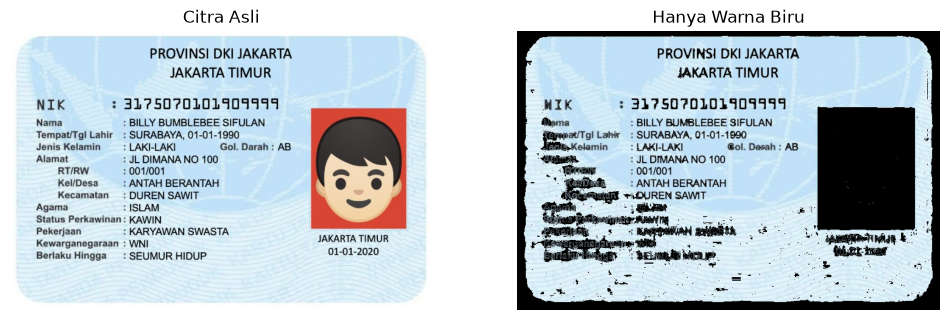

In [14]:
img_bgr = cv.imread(PATH + 'ktp_fulan.jpg')
img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)
img_hsv = cv.cvtColor(img_bgr, cv.COLOR_BGR2HSV)

# Rentang warna biru pada HSV sesuai ketentuan modul
lower_blue = np.array([85, 25, 40])
upper_blue = np.array([130, 255, 255])
mask_blue = cv.inRange(img_hsv, lower_blue, upper_blue)

# Terapkan masking
blue_only = cv.bitwise_and(img_rgb, img_rgb, mask=mask_blue)

# Ubah latar yang di-mask menjadi hitam agar sesuai contoh
black_bg = np.zeros_like(img_rgb)
blue_segmented = np.where(mask_blue[:, :, None] == 255, blue_only, black_bg)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1), plt.imshow(img_rgb), plt.title('Citra Asli'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(blue_segmented), plt.title('Hanya Warna Biru'), plt.axis('off')
plt.show()

In [16]:
pip install pytesseract opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


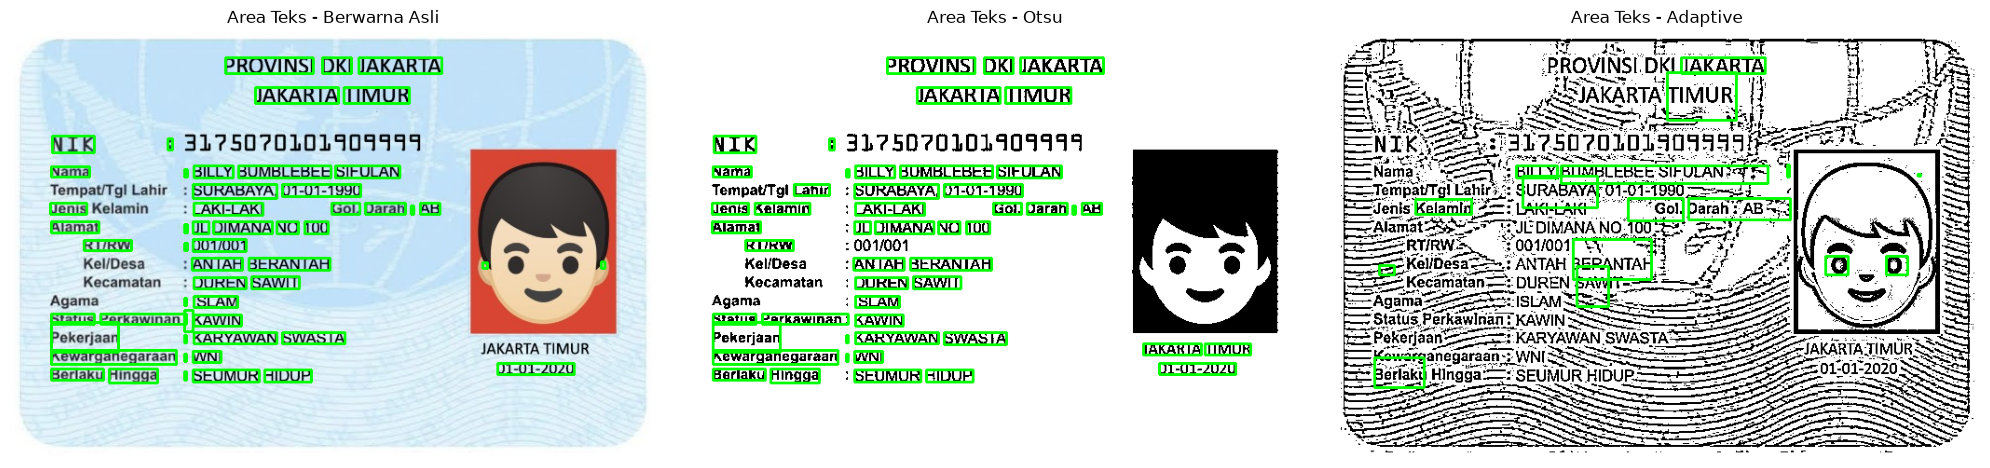

HASIL OCR BERWARNA (Avg Confidence: 90.87)
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 31?5020101409911
Nama : BILLY BUMBLEBEE SIFULAN
Tempat#Tgl Lahir: SURABAYA, 01-01-1990
Jenis Kelamin: LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RTIRW : 001/001

KollDesa — : ANTAH BERANTAH N 4

Kecamatan  : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR,
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


HASIL OCR OTSU (Avg Confidence: 91.20)
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK 1 3)5?5D20101401114
Nama : BILLY BUMBLEBEE SIFULAN
TempatiTgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin —: LAKI-LAKI Got, Darah : AB
Alamat ? JL DIMANA NO 100

RTIRW 1 001/001

KellDesa — : ANTAH BERANTAH

Kecamatan: DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020


HASIL OCR ADAPTIVE (Avg Confidence: 76.50)
ap 1 ES NAN ESA FAN t T
S8 'PROVINS

In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
import os


FILE_NAME = 'ktp_fulan.jpg'
pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'
# Pengecekan apakah file gambar ada agar tidak terjadi error !_src0.empty()
if not os.path.exists(FILE_NAME):
    print(f"ERROR: File '{FILE_NAME}' tidak ditemukan! Pastikan file berada di folder yang sama dengan script ini.")
    exit()

img_ktp = cv.imread(FILE_NAME)
gray_ktp = cv.cvtColor(img_ktp, cv.COLOR_BGR2GRAY)

# 1. Siapkan 3 citra untuk dibandingkan: Berwarna, Otsu, dan Adaptive
img_color = img_ktp.copy()
_, img_otsu = cv.threshold(gray_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adaptive = cv.adaptiveThreshold(gray_ktp, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

# Fungsi untuk membaca teks OCR dan menggambar kotak hijau (confidence > 60)
def read_ocr_and_draw(image, is_color=False):
    # Menggunakan model bahasa indonesia (--l ind)
    custom_config = r'-l ind --oem 3 --psm 6'
    
    # Dapatkan data bounding box dan confidence
    d = pytesseract.image_to_data(image, config=custom_config, output_type=Output.DICT)
    n_boxes = len(d['text'])
    
    display_img = image.copy()
    if not is_color:
        display_img = cv.cvtColor(display_img, cv.COLOR_GRAY2BGR)
        
    confidences = []
    
    for i in range(n_boxes):
        conf = int(d['conf'][i])
        # Filter confidence > 60 sesuai instruksi modul
        if conf > 60:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            cv.rectangle(display_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
            confidences.append(conf)
            
    # Ekstraksi Teks murni
    text_result = pytesseract.image_to_string(image, config=custom_config)
    avg_conf = sum(confidences) / len(confidences) if confidences else 0
    
    return display_img, text_result, avg_conf

# 2 & 3. Eksekusi OCR pada ketiga citra
res_color_img, text_color, conf_color = read_ocr_and_draw(img_color, True)
res_otsu_img, text_otsu, conf_otsu = read_ocr_and_draw(img_otsu, False)
res_adapt_img, text_adapt, conf_adapt = read_ocr_and_draw(img_adaptive, False)

# Tampilkan gambar dengan kotak hijau menggunakan Matplotlib
plt.figure(figsize=(20, 10))
plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(res_color_img, cv.COLOR_BGR2RGB))
plt.title('Area Teks - Berwarna Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(res_otsu_img, cv.COLOR_BGR2RGB))
plt.title('Area Teks - Otsu')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(res_adapt_img, cv.COLOR_BGR2RGB))
plt.title('Area Teks - Adaptive')
plt.axis('off')

plt.tight_layout()
plt.show()

# Print hasil string OCR dan Rata-rata Confidence untuk pengisian laporan
print("="*40)
print(f"HASIL OCR BERWARNA (Avg Confidence: {conf_color:.2f})")
print("="*40)
print(text_color)

print("\n" + "="*40)
print(f"HASIL OCR OTSU (Avg Confidence: {conf_otsu:.2f})")
print("="*40)
print(text_otsu)

print("\n" + "="*40)
print(f"HASIL OCR ADAPTIVE (Avg Confidence: {conf_adapt:.2f})")
print("="*40)
print(text_adapt)

1. Citra masukan mana yang menghasilkan pembacaan paling tepat?
Berdasarkan contoh hasil pada modul, citra hasil Segmentasi Adaptive Thresholding (atau Otsu) menghasilkan pembacaan yang paling tepat dibandingkan citra berwarna asli. Buktinya dapat dilihat dari jumlah item yang terbaca sempurna; pada citra berwarna, Tesseract kesulitan membaca NIK dan sering menyisipkan karakter aneh, sedangkan pada citra yang telah dithreshold (Adaptive/Otsu), angka NIK 3175070101909999 dan nama dapat terbaca dengan bersih dan akurat.   
2. Sebutkan minimal dua kesalahan pembacaan:
Berdasarkan contoh pembacaan di modul, dua kesalahan umum yang terjadi adalah:   Angka terbaca sebagai simbol/huruf lain: Pada citra berwarna, NIK 3175070101909999 terbaca salah menjadi 31?50?01014041419.   Huruf tertukar akibat noise: Teks DUREN SAWIT terbaca menjadi DUREN SANIT pada citra berwarna, atau OUREN SAWIT pada citra Otsu.   
3. Apakah segmentasi selalu meningkatkan ketepatan OCR?
Ya, dalam kasus dokumen bertekstur seperti KTP, segmentasi (terutama binarisasi dengan thresholding) sangat meningkatkan ketepatan OCR. Tesseract bekerja paling optimal pada citra biner (hitam-putih tegas). Segmentasi menghilangkan elemen pengganggu (noise) sehingga kontur huruf dan angka menjadi jauh lebih jelas dibandingkan membaca langsung dari citra RGB.   
4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
Warna latar belakang gradasi biru dan pola watermark (guilloche) pada KTP menurunkan tingkat kontras antara teks (foreground) dan latar belakang (background). Hal ini membuat mesin OCR kebingungan membedakan mana tepi huruf dan mana pola latar, sehingga memicu kesalahan pembacaan (misal, pola latar dianggap sebagai garis huruf teks atau tanda baca ekstra).   
5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?Secara umum ya, tetapi tidak selalu mutlak. Nilai confidence yang tinggi menunjukkan bahwa mesin OCR sangat yakin dengan tebakannya. Jika citra bersih (seperti hasil Adaptive Thresholding), confidence tinggi biasanya berbanding lurus dengan kecocokan teks yang tinggi. Namun, jika ada noise yang menyerupai huruf tertentu, OCR bisa saja memberikan confidence yang tinggi pada tebakan yang ternyata salah (misalnya sangat yakin membaca noda hitam sebagai titik atau koma).

Perbandingan Hasil Pembacaan Teks
